In [3]:
import numpy as np
from helpers.model import *
from helpers.plotting import *

In [4]:
# Partially written with AI to help with the residual rotor-gyroscopic trim. 

R_c = 2.0  # m
v_c = 0.5  # m/s
w_c = v_c / R_c  # 0.25 rad/s
a_c = v_c**2 / R_c  # 0.125 m/s^2
z_c = 1.0  # m

x0_c = 2
y0_c = 0
z0_c = 1

vx0_c = 0
vy0_c = 0.5
vz0_c = 0

phi0_c = -np.atan2(a_c, g)
theta0_c = 0
psi0_c = np.pi/2

w2_0 = w_c * np.sin(phi0_c)
w3_0 = w_c * np.cos(phi0_c)

omega1_c = 0
omega2_c = 0.25*np.sin(phi0_c)
omega3_c = 0.25*np.cos(phi0_c)

T_c = m*np.sqrt(g**2 + a_c**2)
M1_c = (I3 - I2)*omega2_c*omega3_c

T0_c = np.array([T_c/4, T_c/4 + M1_c/(2*l), T_c/4, T_c/4 - M1_c/(2*l)])
Omega0_c = np.sqrt(T0_c/k_T)

E0_c = 0

u_c = k_Q * Omega0_c**2 # N m

Kp_pos = np.array([6.0, 6.0, 12.0])
Kd_pos = np.array([4.5, 4.5, 7.0])
Kp_att = np.array([35.0, 35.0, 15.0])
Kd_att = np.array([10.0, 10.0, 6.0])
K_omega = 0.002

def u_circle(r, t):
    pos = r[0:3]
    vel = r[3:6]
    phi, theta, psi = r[6:9]
    w = r[9:12]
    Omega = r[12:16]

    ang = w_c * t
    pos_d = np.array([R_c * np.cos(ang), R_c * np.sin(ang), z_c])
    vel_d = np.array([-v_c * np.sin(ang), v_c * np.cos(ang), 0.0])
    acc_d = np.array([-a_c * np.cos(ang), -a_c * np.sin(ang), 0.0])

    psi_d = np.pi / 2.0 + ang
    w_d = np.array([0.0, w2_0, w3_0])

    a_cmd = acc_d + Kp_pos * (pos_d - pos) + Kd_pos * (vel_d - vel)
    T_d = max(m * (a_cmd[2] + g) / (np.cos(theta) * np.cos(phi)), 0.0)
    phi_d = (a_cmd[0] * np.sin(psi) - a_cmd[1] * np.cos(psi)) / g
    theta_d = (a_cmd[0] * np.cos(psi) + a_cmd[1] * np.sin(psi)) / g

    psi_err = (psi_d - psi + np.pi) % (2 * np.pi) - np.pi
    att_err = np.array([phi_d - phi, theta_d - theta, psi_err])
    M_d = np.array([I1, I2, I3]) * (Kp_att * att_err + Kd_att * (w_d - w))
    M_d[0] += M1_c

    T1_d = T_d / 4.0 - M_d[1] / (2.0 * l) - (k_T / (4.0 * k_Q)) * M_d[2]
    T2_d = T_d / 4.0 + M_d[0] / (2.0 * l) + (k_T / (4.0 * k_Q)) * M_d[2]
    T3_d = T_d / 4.0 + M_d[1] / (2.0 * l) - (k_T / (4.0 * k_Q)) * M_d[2]
    T4_d = T_d / 4.0 - M_d[0] / (2.0 * l) + (k_T / (4.0 * k_Q)) * M_d[2]

    Omega_d = np.sqrt(np.maximum(np.array([T1_d, T2_d, T3_d, T4_d]), 0.0) / k_T)

    Q_i = k_Q * Omega**2
    u = Q_i + K_omega * (Omega_d - Omega)
    return np.clip(u, 0.0, 0.10) 

f_circle = lambda r, t : state_dot(r, t, u_circle(r, t))

r0_c = np.array([x0_c, y0_c, z0_c, vx0_c, vy0_c, vz0_c, phi0_c, theta0_c, psi0_c, omega1_c, omega2_c, omega3_c, Omega0_c[0], Omega0_c[1], Omega0_c[2], Omega0_c[3], E0_c])

r_circle, times_c = forward_euler(f_circle, r0_c, 60, 0.001)

x_c_desired = R_c*np.cos(w_c*times_c)
y_c_desired = R_c*np.sin(w_c*times_c)

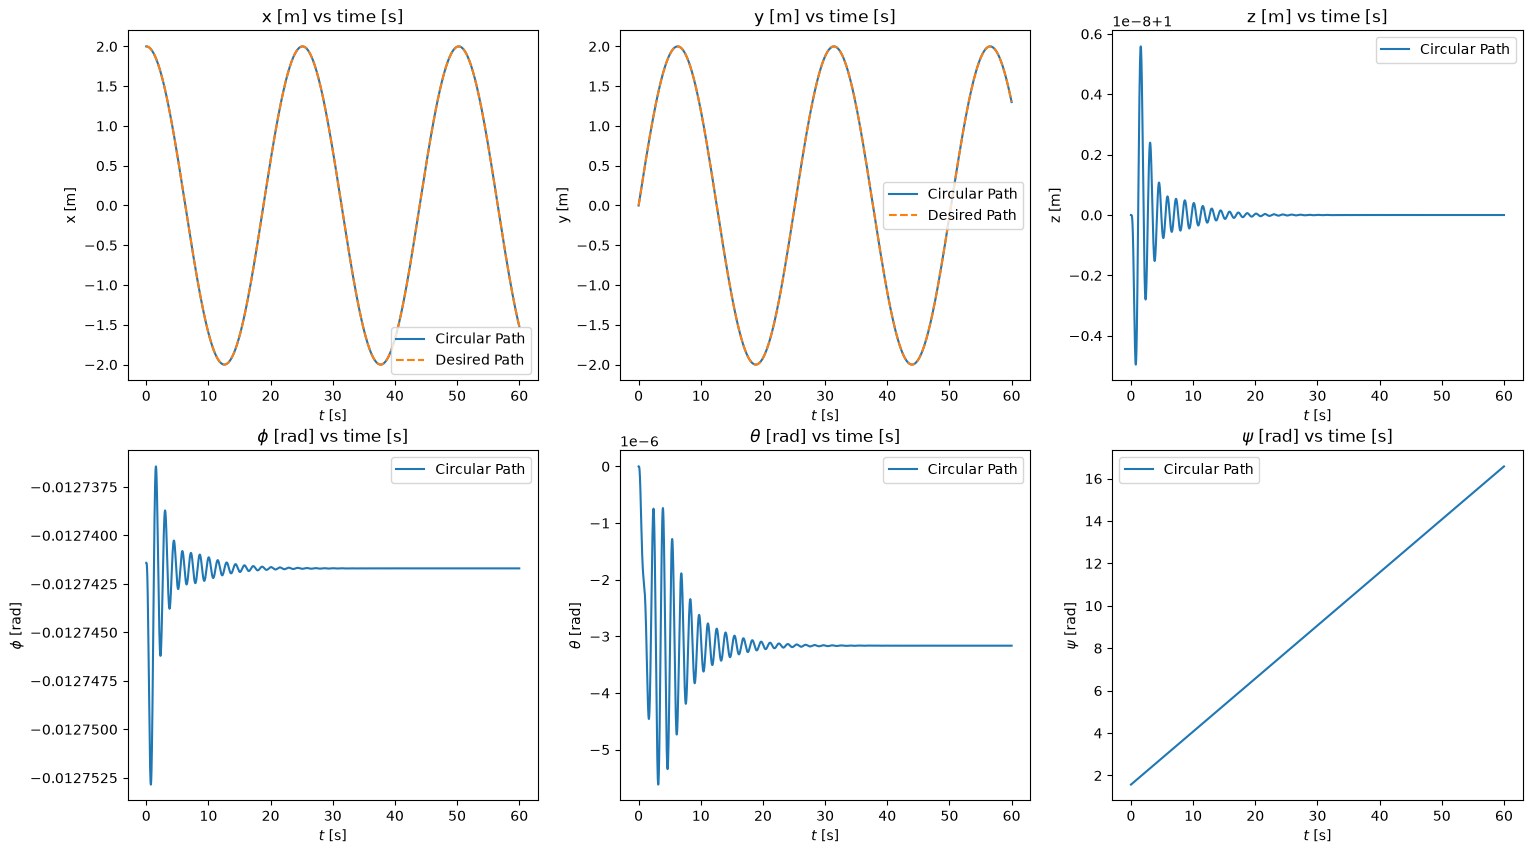

In [5]:
fig = plotDegreesOfFreedom(times_c, r_circle, 'Circular Path')
axes = fig.axes

axes[0].plot(times_c, x_c_desired, label='Desired Path', ls='--')
axes[0].legend()
axes[1].plot(times_c, y_c_desired, label='Desired Path', ls='--')
axes[1].legend()

In [31]:
max_x_c_error = np.max(np.abs(r_circle[:,0] - x_c_desired))
max_y_c_error = np.max(np.abs(r_circle[:,1] - y_c_desired))
E_circle_f = r_circle[-1][16]

max_radius_error = np.max(np.abs(np.sqrt(r_circle[:,0]**2 + r_circle[:,1]**2) - R_c))
max_z_c_error = np.max(np.abs(r_circle[:,2] - 1.0))
max_speed_error = np.max(np.abs(np.sqrt(r_circle[:,3]**2 + r_circle[:,4]**2) - v_c))

print(f'Maximum error x: {max_x_c_error} m')
print(f'Maximum error y: {max_y_c_error} m')
print(f'Energy used: {E_circle_f} J\n')

print(f'Maximum Radius Error: {max_radius_error} m')
print(f'Maximum Altitude Error: {max_z_c_error} m')
print(f'Maximum Velocity Error: {max_speed_error} m/s')

Maximum error x: 4.535973032537832e-05 m
Maximum error y: 4.582053684920595e-05 m
Energy used: 8792.457558064592 J

Maximum Radius Error: 4.706741043492002e-05 m
Maximum Altitude Error: 5.587208251611742e-09 m
Maximum Velocity Error: 1.692111365625415e-05 m/s


In [7]:
fig.savefig("Figures/PG2-DegreesOfFreedom.pdf", format="pdf", bbox_inches="tight")